Data shape: (592, 16)
Features: ['location_urban', 'location_rural', 'hh_size1', 'hh_size2', 'hh_size3', 'hh_size4', 'm_0_to_29', 'f_0_to_29', 'm_30_to_59', 'f_30_to_59', 'm_gt_60', 'f_gt_60', 'edu_non', 'edu_low', 'edu_middle', 'edu_high']

Cluster sizes:
1    358
2    169
3     65
Name: count, dtype: int64


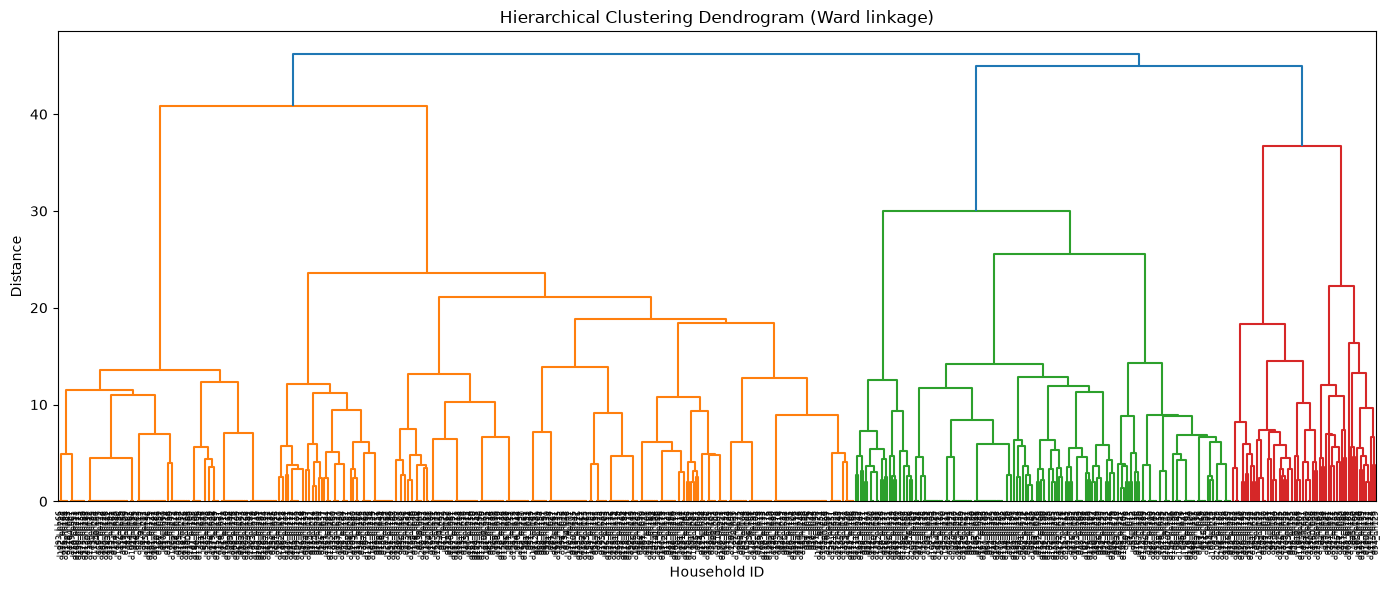


Saved: survey_with_clusters.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler

# ---------------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------------
df = pd.read_csv("artifical_survey.csv")

# Household ID is an identifier, not a feature
hh_ids = df["hh_id"]
X = df.drop(columns=["hh_id"])

print(f"Data shape: {X.shape}")
print(f"Features: {list(X.columns)}")

# ---------------------------------------------------------------
# 2. OPTIONAL: aggregate education into a single ordinal score
#    (edu_non, edu_low, edu_middle, edu_high -> weighted score)
# ---------------------------------------------------------------
# Uncomment if you want a compact education feature instead of dummies
# X["edu_score"] = (X["edu_low"]*1 + X["edu_middle"]*2 + X["edu_high"]*3)
# X = X.drop(columns=["edu_non", "edu_low", "edu_middle", "edu_high"])

# ---------------------------------------------------------------
# 3. STANDARDISE (important for distance-based clustering)
#    Binary columns will be scaled too; if you want to keep binaries
#    as-is, scale only the continuous-looking ones.
# ---------------------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns, index=hh_ids)

# ---------------------------------------------------------------
# 4. HIERARCHICAL CLUSTERING
# ---------------------------------------------------------------
# Ward linkage minimises within-cluster variance (good for survey data)
Z = linkage(X_scaled, method="ward", metric="euclidean")

# Choose number of clusters — try 3 (adjust based on your needs)
n_clusters = 3
clusters = fcluster(Z, t=n_clusters, criterion="maxclust")
X_scaled["cluster"] = clusters

print("\nCluster sizes:")
print(pd.Series(clusters).value_counts().sort_index())

# ---------------------------------------------------------------
# 5. DENDROGRAM (cluster tree)
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(
    Z,
    labels=hh_ids.values,
    leaf_rotation=90,
    leaf_font_size=6,
    ax=ax,
    color_threshold=Z[-(n_clusters - 1), 2],  # cut line for n_clusters
)
ax.set_title("Hierarchical Clustering Dendrogram (Ward linkage)")
ax.set_xlabel("Household ID")
ax.set_ylabel("Distance")
plt.tight_layout()
plt.savefig("dendrogram.png", dpi=150)
plt.show()


# ---------------------------------------------------------------
# 8. EXPORT RESULTS
# ---------------------------------------------------------------
result = df.copy()
result["cluster"] = clusters
result.to_csv("survey_with_clusters.csv", index=False)
print("\nSaved: survey_with_clusters.csv")

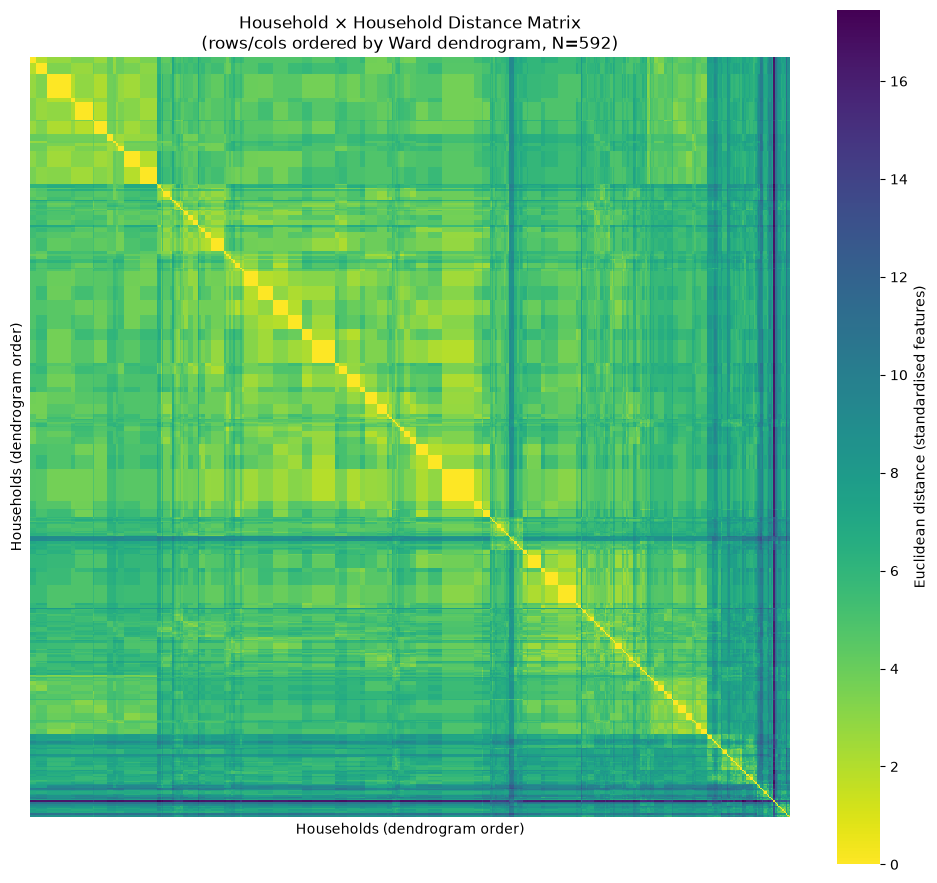

In [5]:
fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(
    D_ordered,
    cmap="viridis_r",          # dark = close, bright = far
    square=True,
    cbar_kws={"label": "Euclidean distance (standardised features)"},
    xticklabels=False,
    yticklabels=False,
    ax=ax,
)
ax.set_title(f"Household × Household Distance Matrix\n(rows/cols ordered by Ward dendrogram, N={len(hh_ids)})")
ax.set_xlabel("Households (dendrogram order)")
ax.set_ylabel("Households (dendrogram order)")
plt.tight_layout()
plt.savefig("distance_heatmap_full.png", dpi=150)
plt.show()

In [6]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, leaves_list, fcluster
from sklearn.preprocessing import StandardScaler

# ---------------------------------------------------------------
# 1. LOAD + SCALE (same as before)
# ---------------------------------------------------------------
df = pd.read_csv("artifical_survey.csv")
hh_ids = df["hh_id"].values
X = df.drop(columns=["hh_id"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------------------------------------------------------------
# 2. DISTANCE MATRIX
# ---------------------------------------------------------------
D = squareform(pdist(X_scaled, metric="euclidean"))
print("Distance matrix shape:", D.shape)

# ---------------------------------------------------------------
# 3. CSV A — square matrix, labelled by hh_id
# ---------------------------------------------------------------
D_df = pd.DataFrame(D, index=hh_ids, columns=hh_ids)
D_df.index.name = "hh_id"

D_df.to_csv("distance_matrix.csv")
print("Saved: distance_matrix.csv  (shape", D_df.shape, ")")

Distance matrix shape: (592, 592)
Saved: distance_matrix.csv  (shape (592, 592) )
